# BNPL Financial Default Risk — Model Development

Machine Learning (AIML) · Assignment 2

This notebook is the development trail behind the five models shipped in this repo:
exploratory analysis, the reasoning for each engineered feature, training, tuning
and evaluation. `train_models.py` is the production version of the same workflow;
running it reproduces the artefacts in `model/`.

**Target:** `Default_Risk` ∈ {Low, Medium, High} — a 3-class problem with
88 / 7 / 5 class imbalance.

## 1. Setup

In [1]:
# This notebook lives in notebooks/ but every path below is relative to the
# repository root, and it imports features.py / train_models.py from there.
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))
print("working directory:", Path.cwd())

working directory: /Users/arjunsingh/Desktop/BITS working/MachineLearning/bnpl-default-risk-ml


In [2]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

import features as F      # shared schema + feature engineering
RANDOM_STATE = 42

In [3]:
raw = pd.read_csv("data/BNPL_Financial_Default_Risk_Dataset.csv")
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

10,000 rows x 11 columns


,Customer_ID,Age,Employment_Status,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Late_Payment_History,Shopping_Category_Most_Frequent,Average_Transaction_Value_USD,Default_Risk
0,C00001,29,Employed,73405.0,637.0,2,193,No,Fashion,118,Low
1,C00002,64,Employed,53732.0,815.0,0,0,No,Electronics,662,Low
2,C00003,26,Freelancer,69930.0,723.0,2,273,No,Fashion,76,Low
3,C00004,19,Employed,96941.0,716.0,3,421,No,Home/Furniture,449,Low
4,C00005,55,Student,15959.0,675.0,2,145,No,Travel,974,Low


## 2. Exploratory data analysis

### 2.1 Structure, missingness and duplicates

In [4]:
raw.info()
print("\nduplicate rows:", raw.duplicated().sum())
print("unique customers:", raw[F.ID_COL].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Customer_ID                      10000 non-null  object 
 1   Age                              10000 non-null  int64  
 2   Employment_Status                10000 non-null  object 
 3   Income_USD                       9695 non-null   float64
 4   Credit_Score                     9702 non-null   float64
 5   Total_BNPL_Active_Loans          10000 non-null  int64  
 6   Total_BNPL_Debt_USD              10000 non-null  int64  
 7   Late_Payment_History             10000 non-null  object 
 8   Shopping_Category_Most_Frequent  10000 non-null  object 
 9   Average_Transaction_Value_USD    10000 non-null  int64  
 10  Default_Risk                     10000 non-null  object 
dtypes: float64(2), int64(4), object(5)
memory usage: 859.5+ KB

duplicate rows: 0
uni

In [5]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(raw) * 100).round(2)
missing

,n_missing,pct
Income_USD,305,3.05
Credit_Score,298,2.98


Only `Income_USD` (3.05%) and `Credit_Score` (2.98%) have gaps. Both are numeric and
both are median-imputed inside the pipeline. Before deciding that, check whether the
missingness itself carries signal.

In [6]:
for col in ["Income_USD", "Credit_Score"]:
    share = pd.crosstab(raw[col].isna(), raw[F.TARGET], normalize="index").round(4)
    share.index = [f"{col} present", f"{col} missing"]
    print(share, "\n")

Default_Risk          High     Low  Medium
Income_USD present  0.0522  0.8799  0.0679
Income_USD missing  0.0492  0.8852  0.0656 

Default_Risk            High     Low  Medium
Credit_Score present  0.0525  0.8801  0.0674
Credit_Score missing  0.0403  0.8792  0.0805 



The class distribution is essentially identical whether or not the value is present,
so the missingness is uninformative — close to missing-at-random. The
`*_Was_Missing` indicator flags are kept anyway: they cost two columns, they make the
imputation honest, and a model is free to ignore them.

### 2.2 Target distribution

,rows,share
Default_Risk,,
Low,8801,88.01%
Medium,678,6.78%
High,521,5.21%


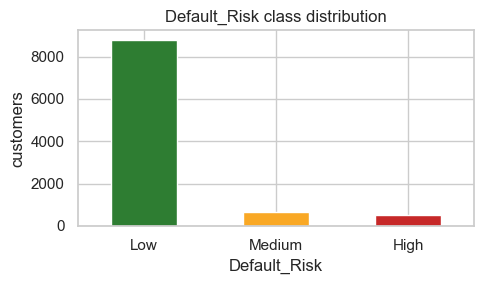

majority-class ('Low') baseline accuracy: 0.8801


In [7]:
counts = raw[F.TARGET].value_counts().reindex(F.CLASS_ORDER)
summary = counts.to_frame("rows")
summary["share"] = (summary["rows"] / len(raw)).map("{:.2%}".format)
display(summary)

ax = counts.plot(kind="bar", color=["#2e7d32", "#f9a825", "#c62828"], figsize=(5, 3))
ax.set_title("Default_Risk class distribution")
ax.set_ylabel("customers")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

print(f"majority-class ('Low') baseline accuracy: {counts['Low'] / len(raw):.4f}")

**88% of customers sit in the Low class.** Predicting `Low` for everybody scores
0.88 accuracy while being useless, so accuracy cannot be the headline metric.
MCC and macro-averaged F1 are used instead — a constant predictor scores **MCC = 0**.

### 2.3 Do the raw numeric columns separate the classes?

In [8]:
raw.groupby(F.TARGET)[F.RAW_NUMERIC].mean().reindex(F.CLASS_ORDER).round(1)

,Age,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Average_Transaction_Value_USD
Default_Risk,,,,,,
Low,34.3,58971.9,675.3,2.1,305.1,330.2
Medium,34.1,22131.7,587.3,3.6,575.4,341.6
High,34.1,11256.0,566.2,4.6,791.9,346.8


**This is the key finding of the EDA.** Age, income, debt and basket size have
near-identical means across the three risk bands. On these raw columns alone a linear
model has very little to work with — the separation is not in any single column.

### 2.4 The categorical columns do separate them

In [9]:
for col in ["Employment_Status", "Late_Payment_History", "Shopping_Category_Most_Frequent"]:
    print(pd.crosstab(raw[col], raw[F.TARGET], normalize="index")[F.CLASS_ORDER].round(3), "\n")

Default_Risk         Low  Medium   High
Employment_Status                      
Employed           0.983   0.015  0.002
Freelancer         0.921   0.056  0.023
Student            0.664   0.190  0.146
Unemployed         0.374   0.258  0.368 

Default_Risk            Low  Medium   High
Late_Payment_History                      
No                    0.946   0.030  0.024
Yes                   0.681   0.182  0.137 

Default_Risk                       Low  Medium   High
Shopping_Category_Most_Frequent                      
Electronics                      0.876   0.070  0.053
Fashion                          0.883   0.066  0.051
Groceries/Essentials             0.895   0.064  0.041
Home/Furniture                   0.883   0.065  0.052
Travel                           0.869   0.073  0.058 



`Employment_Status` is strongly predictive — 36.8% of unemployed customers are High
risk against 0.2% of employed ones — and a prior late payment raises High-risk
likelihood from 2.4% to 13.7%. `Shopping_Category_Most_Frequent` is comparatively flat.

### 2.5 The signal is in the ratios, not the columns

In [10]:
probe = raw.copy()
probe["Debt_To_Monthly_Income"] = probe["Total_BNPL_Debt_USD"] / (probe["Income_USD"] / 12)
probe.groupby(F.TARGET)["Debt_To_Monthly_Income"].describe().reindex(F.CLASS_ORDER).round(3)

,count,mean,std,min,25%,50%,75%,max
Default_Risk,,,,,,,,
Low,8531.0,0.080,0.084,0.000,0.026,0.053,0.108,0.575
Medium,658.0,0.371,0.161,0.026,0.256,0.353,0.467,0.936
High,506.0,0.963,0.562,0.283,0.607,0.806,1.143,5.081


/var/folders/d2/_12cprb516q21gzbh1kz1sfc0000gn/T/ipykernel_46072/2091699315.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=probe, x=F.TARGET, y="Debt_To_Monthly_Income",


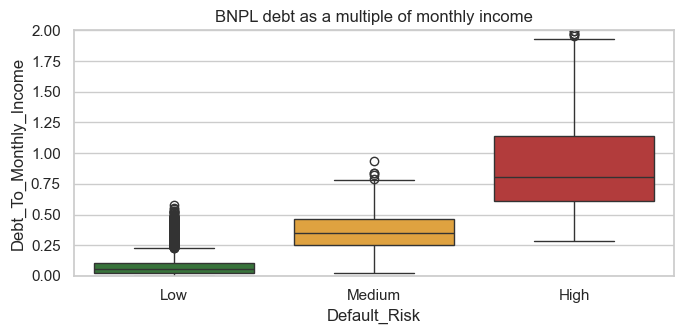

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=probe, x=F.TARGET, y="Debt_To_Monthly_Income",
            order=F.CLASS_ORDER, palette=["#2e7d32", "#f9a825", "#c62828"], ax=ax)
ax.set_ylim(0, 2.0)
ax.set_title("BNPL debt as a multiple of monthly income")
plt.tight_layout(); plt.show()

Debt-to-income separates the classes cleanly where no raw column did — class means of
**0.08 / 0.37 / 0.96** for Low / Medium / High. Neither `Total_BNPL_Debt_USD` nor
`Income_USD` shows this on its own; only their ratio does.

Two consequences drive the rest of the notebook:

1. **Feature engineering is where the performance comes from.** Ratio features are
   built in `features.py`.
2. **Low and Medium still overlap** (Medium's interquartile range is 0.26–0.47, inside
   Low's upper tail), so a curved decision boundary should beat a straight one —
   the reason the RBF SVM is expected to lead.

## 3. Feature engineering

Implemented in `features.py` so that training and the Streamlit app derive identical columns.

In [12]:
X_all = F.build_feature_frame(raw)
print(f"{len(F.RAW_NUMERIC) + len(F.RAW_CATEGORICAL)} raw predictors -> {X_all.shape[1]} model features")
print(f"  numeric     ({len(F.NUMERIC_FEATURES)}): {F.NUMERIC_FEATURES}")
print(f"  categorical ({len(F.CATEGORICAL_FEATURES)}): {F.CATEGORICAL_FEATURES}")
X_all.head()

9 raw predictors -> 18 model features
  numeric     (13): ['Age', 'Income_USD', 'Credit_Score', 'Total_BNPL_Active_Loans', 'Total_BNPL_Debt_USD', 'Average_Transaction_Value_USD', 'Monthly_Income_USD', 'Debt_To_Monthly_Income', 'Debt_Per_Active_Loan', 'Txn_To_Monthly_Income', 'Credit_Score_Per_Loan', 'Income_Was_Missing', 'Credit_Score_Was_Missing']
  categorical (5): ['Employment_Status', 'Late_Payment_History', 'Shopping_Category_Most_Frequent', 'Age_Band', 'Credit_Score_Band']


,Age,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Average_Transaction_Value_USD,Monthly_Income_USD,Debt_To_Monthly_Income,Debt_Per_Active_Loan,Txn_To_Monthly_Income,Credit_Score_Per_Loan,Income_Was_Missing,Credit_Score_Was_Missing,Employment_Status,Late_Payment_History,Shopping_Category_Most_Frequent,Age_Band,Credit_Score_Band
0,29,73405.0,637.0,2,193,118,6117.083333,0.031546,96.500000,0.019287,318.500000,0,0,Employed,No,Fashion,25-34,Fair
1,64,53732.0,815.0,0,0,662,4477.666667,0.000000,0.000000,0.147812,815.000000,0,0,Employed,No,Electronics,55+,Excellent
2,26,69930.0,723.0,2,273,76,5827.500000,0.046839,136.500000,0.013039,361.500000,0,0,Freelancer,No,Fashion,25-34,Good
3,19,96941.0,716.0,3,421,449,8078.416667,0.052108,140.333333,0.055573,238.666667,0,0,Employed,No,Home/Furniture,18-24,Good
4,55,15959.0,675.0,2,145,974,1329.916667,0.108947,72.500000,0.731826,337.500000,0,0,Student,No,Travel,55+,Good


Every derived column is a function of its own row only, so deriving before the
train/test split leaks nothing between the halves. The two `*_Was_Missing` flags are
computed *before* the imputer runs, so the fact that a value was absent survives
imputation.

In [13]:
corr = X_all[F.NUMERIC_FEATURES].corrwith(
    raw[F.TARGET].map({"Low": 0, "Medium": 1, "High": 2})
).sort_values(key=abs, ascending=False)
corr.to_frame("corr_with_risk_rank").round(3)

,corr_with_risk_rank
Debt_To_Monthly_Income,0.785
Income_USD,-0.447
Monthly_Income_USD,-0.447
Txn_To_Monthly_Income,0.417
Credit_Score,-0.405
Total_BNPL_Debt_USD,0.393
Total_BNPL_Active_Loans,0.358
Credit_Score_Per_Loan,-0.346
Debt_Per_Active_Loan,0.175
Average_Transaction_Value_USD,0.017


Ranking the numeric features by correlation with the ordinal risk level confirms the
EDA: the engineered ratios dominate, and the raw columns they are built from sit near
zero on their own.

## 4. Train / test split

Stratified 80/20. The test half is written to `test_data.csv` and is what the Streamlit app scores — no model sees it during training or tuning.

In [14]:
from sklearn.model_selection import train_test_split

raw_train, raw_test = train_test_split(
    raw, test_size=0.20, stratify=raw[F.TARGET], random_state=RANDOM_STATE
)
X_train, X_test = F.build_feature_frame(raw_train), F.build_feature_frame(raw_test)
y_train, y_test = raw_train[F.TARGET], raw_test[F.TARGET]

print(f"train {len(X_train):,}   test {len(X_test):,}")
pd.DataFrame({
    "train": y_train.value_counts(normalize=True).reindex(F.CLASS_ORDER),
    "test":  y_test.value_counts(normalize=True).reindex(F.CLASS_ORDER),
}).round(4)

train 8,000   test 2,000


,train,test
Default_Risk,,
Low,0.8801,0.880
Medium,0.0678,0.068
High,0.0521,0.052


## 5. Preprocessing pipeline

All preprocessing lives inside each model's `Pipeline`, so a saved model is self-contained and nothing can leak across the split.

In [15]:
from train_models import build_preprocessor

prep = build_preprocessor().fit(X_train)
print(f"{X_train.shape[1]} features -> {len(prep.get_feature_names_out())} columns after one-hot encoding")

18 features -> 35 columns after one-hot encoding


## 6. Train and tune the five models

Each classifier is tuned with `GridSearchCV` on **macro F1**, which weights the
104-row High class equally with the 1,760-row Low class. `class_weight="balanced"` is
used wherever the estimator supports it; KNN and GaussianNB have no such parameter,
which turns out to matter a great deal for KNN.

In [16]:
from train_models import MODEL_SPECS
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

fitted, search_rows = {}, []
for slug, (name, estimator, grid, folds) in MODEL_SPECS.items():
    search = GridSearchCV(
        Pipeline([("prep", build_preprocessor()), ("clf", estimator)]),
        param_grid=grid, scoring="f1_macro", cv=folds, n_jobs=-1,
    ).fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    search_rows.append({"model": name, "cv_f1_macro": round(search.best_score_, 4),
                        "best_params": search.best_params_})
    print(f"{name:<24} cv f1_macro={search.best_score_:.4f}  {search.best_params_}")

pd.DataFrame(search_rows).set_index("model")

Logistic Regression      cv f1_macro=0.8725  {'clf__C': 10.0}


Decision Tree            cv f1_macro=0.8441  {'clf__max_depth': None, 'clf__min_samples_leaf': 5}


KNN                      cv f1_macro=0.7838  {'clf__n_neighbors': 5, 'clf__weights': 'distance'}
Naive Bayes              cv f1_macro=0.5913  {'clf__var_smoothing': 0.001}


Support Vector Machine   cv f1_macro=0.8718  {'clf__C': 10.0, 'clf__gamma': 'scale'}


,cv_f1_macro,best_params
model,,
Logistic Regression,0.8725,{'clf__C': 10.0}
Decision Tree,0.8441,"{'clf__max_depth': None, 'clf__min_samples_lea..."
KNN,0.7838,"{'clf__n_neighbors': 5, 'clf__weights': 'dista..."
Naive Bayes,0.5913,{'clf__var_smoothing': 0.001}
Support Vector Machine,0.8718,"{'clf__C': 10.0, 'clf__gamma': 'scale'}"


## 7. Evaluation on the hold-out split

Six metrics, as required. Precision / recall / F1 are macro-averaged; AUC is one-vs-rest macro.

In [17]:
from train_models import evaluate

classes = F.CLASS_ORDER
rows = [evaluate(name, pipe, X_test, y_test, classes) for name, pipe in fitted.items()]

comparison = pd.DataFrame([{
    "ML Model Name": r["model"],
    "Accuracy":  r["accuracy"],
    "AUC":       r["auc_ovr_macro"],
    "Precision": r["precision_macro"],
    "Recall":    r["recall_macro"],
    "F1":        r["f1_macro"],
    "MCC":       r["mcc"],
} for r in rows]).set_index("ML Model Name").round(4)

comparison.style.format("{:.4f}").highlight_max(axis=0, color="#a5d6a7")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9450,0.9905,0.8202,0.9332,0.8639,0.7951
Decision Tree,0.9490,0.9405,0.8005,0.8706,0.8324,0.7865
KNN,0.9445,0.9562,0.8233,0.7558,0.7859,0.7288
Naive Bayes,0.8205,0.9346,0.5190,0.6923,0.5624,0.4737
Support Vector Machine,0.9605,0.9912,0.8546,0.9149,0.8805,0.8353


### 7.1 Per-class recall — where the models really differ

In [18]:
per_class = pd.DataFrame({
    r["model"]: {c: r["per_class"][c]["recall"] for c in classes} for r in rows
}).T[classes].round(3)
per_class.columns = [f"Recall ({c})" for c in classes]
per_class

,Recall (Low),Recall (Medium),Recall (High)
Logistic Regression,0.948,0.890,0.962
Decision Tree,0.968,0.750,0.894
KNN,0.989,0.500,0.779
Naive Bayes,0.854,0.338,0.885
Support Vector Machine,0.971,0.860,0.913


Overall accuracy spans a narrow 0.82–0.96 and hides the real differences. KNN is the
clearest example: 0.9445 accuracy — within half a point of the SVM — while missing
**half** of all Medium-risk customers. Having no `class_weight` parameter, it lets the
88% Low majority dominate every neighbourhood vote.

### 7.2 Confusion matrices

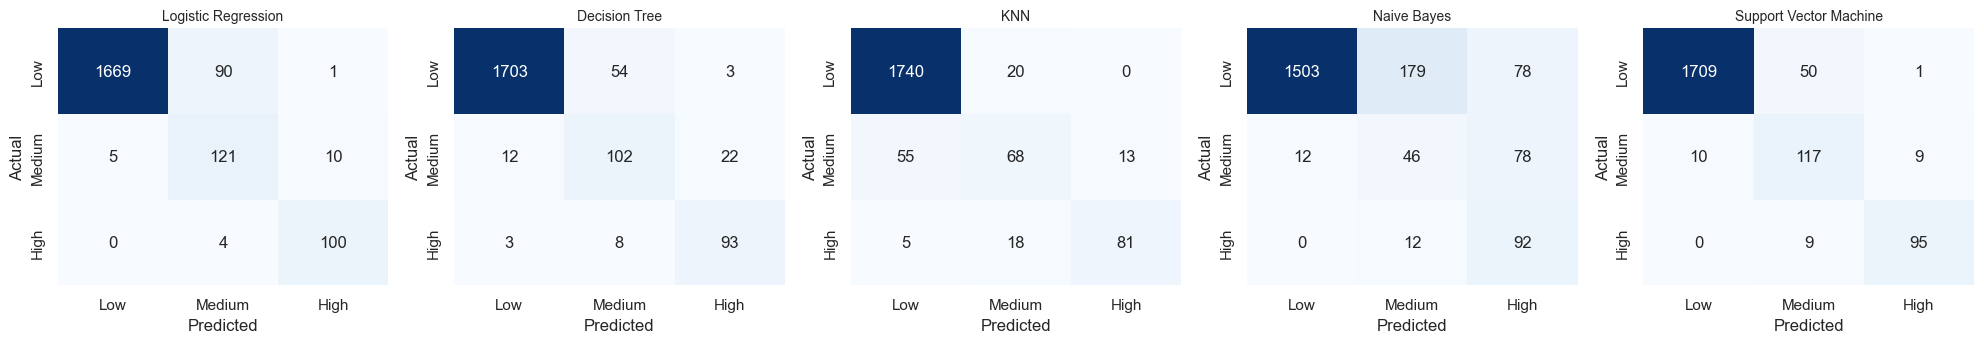

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, r in zip(axes, rows):
    sns.heatmap(np.array(r["confusion_matrix"]), annot=True, fmt="d", cmap="Blues",
                cbar=False, xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(r["model"], fontsize=10)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [20]:
# The business-critical error: a High-risk customer approved as Low risk.
pd.DataFrame([{
    "model": r["model"],
    "High misread as Low": np.array(r["confusion_matrix"])[2, 0],
    "High misread as Medium": np.array(r["confusion_matrix"])[2, 1],
    "High caught": np.array(r["confusion_matrix"])[2, 2],
} for r in rows]).set_index("model")

,High misread as Low,High misread as Medium,High caught
model,,,
Logistic Regression,0,4,100
Decision Tree,3,8,93
KNN,5,18,81
Naive Bayes,0,12,92
Support Vector Machine,0,9,95


### 7.3 Metric comparison

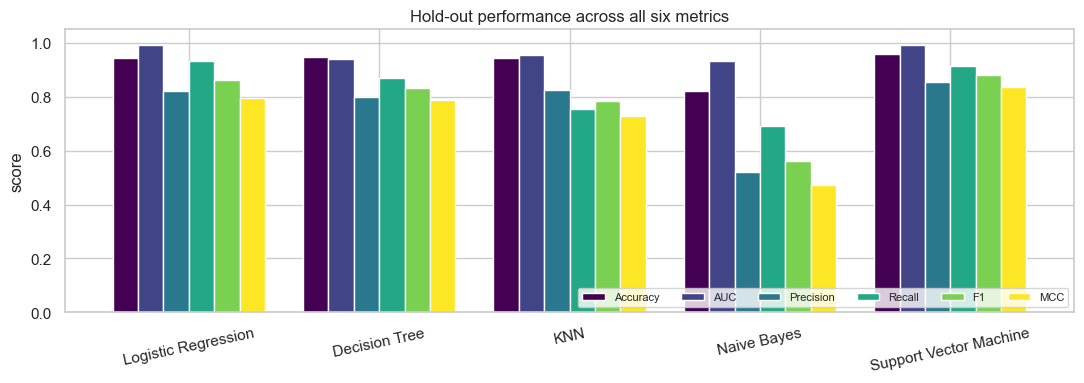

In [21]:
ax = comparison.plot(kind="bar", figsize=(11, 4), width=0.8, colormap="viridis")
ax.set_ylim(0, 1.05); ax.set_ylabel("score"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=12)
ax.legend(ncol=6, fontsize=8, loc="lower right")
ax.set_title("Hold-out performance across all six metrics")
plt.tight_layout(); plt.show()

## 8. Conclusions

| Model | Verdict |
|---|---|
| Logistic Regression | Strong second (MCC 0.7951) and the **best macro recall of all five** (0.9332), catching 96.2% of High-risk customers. The engineered ratios made a near-linear boundary viable. Over-flags Low as Medium (precision 0.563 on Medium). Fully auditable coefficients. |
| Decision Tree | Good accuracy (0.9490) but the **worst AUC** (0.9405) — the signature of hard, poorly calibrated leaf probabilities. Overfits despite `min_samples_leaf=5`. |
| KNN | Weakest of the four competent models (MCC 0.7288). Misses 50% of Medium. No `class_weight`, and 35 one-hot dimensions dilute the distance metric. |
| Naive Bayes | **Worst overall** (MCC 0.4737) and below the 0.88 majority baseline on accuracy. Its independence assumption is violated by both the engineered ratios and the one-hot columns. AUC 0.9346 shows it ranks acceptably but thresholds badly. |
| **Support Vector Machine** | **Winner — best on 5 of 6 metrics** (MCC 0.8353). The RBF kernel handles the Low/Medium overlap that the EDA predicted would be the hard region, and no High-risk customer is misread as Low. |

**Winner: Support Vector Machine (RBF).** Logistic Regression is the recommended
fallback — within 0.04 MCC, better on High-risk recall, far cheaper to train and
explainable to a credit-risk committee.

## 9. Persist the artefacts

`train_models.py` is the canonical path; this cell confirms the notebook reproduces the same numbers.

In [22]:
saved = {r["model"]: r for r in json.loads(open("model/metrics.json").read())["results"]}
check = pd.DataFrame([{
    "model": r["model"],
    "notebook MCC": round(r["mcc"], 4),
    "train_models.py MCC": round(saved[r["model"]]["mcc"], 4),
    "match": abs(r["mcc"] - saved[r["model"]]["mcc"]) < 1e-9,
} for r in rows]).set_index("model")
check

,notebook MCC,train_models.py MCC,match
model,,,
Logistic Regression,0.7951,0.7951,True
Decision Tree,0.7865,0.7865,True
KNN,0.7288,0.7288,True
Naive Bayes,0.4737,0.4737,True
Support Vector Machine,0.8353,0.8353,True


To regenerate everything from a clean checkout:

```bash
python train_models.py   # rewrites model/*.joblib, metrics.json, metadata.json, test_data.csv
streamlit run app.py     # serves the saved models, never refits
```